# Lecture 13: Feature engineering and selection

[Lecture notes](https://ubc-cs.github.io/cpsc330-book/book/13_feature-engineering-selection.html)

- **Engineer:** change the representation so a model can learn useful patterns.
- **Select:** retain a useful subset of the available features.
- **Evaluate:** compare the complete pipelines using cross-validation.
- Connect to Lecture 12: importance describes a fitted model; removing a feature requires refitting and evaluation.

## Setup and imports

- Run cells in order using this directory's `.venv`.
- Data: `data/california_housing.csv` and scikit-learn's breast cancer dataset.
- Use training data for exploration and cross-validation; reserve test data.
- Compare representations with the same folds and scoring metric.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import numpy.random as npr
import pandas as pd
from sklearn.compose import (
    ColumnTransformer,
    TransformedTargetRegressor,
    make_column_transformer,
)
sys.path.append(os.path.join(os.path.abspath(".."), (".."), "code"))
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, RidgeCV
from sklearn.metrics import make_scorer, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, cross_validate, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
DATA_DIR = "data/"
from sklearn.svm import SVC

## 1. Feature interactions: make XOR separable

- A **feature cross** combines existing features into a new input.
- A product $x_1x_2$ lets a linear model use an interaction.

| $x_1$ | $x_2$ | Target |
|---|---|---|
| 1 | 1 | 0 |
| -1 | 1 | 1 |
| 1 | -1 | 1 |
| -1 | -1 | 0 |

**Predict:** Can one straight line separate these classes?

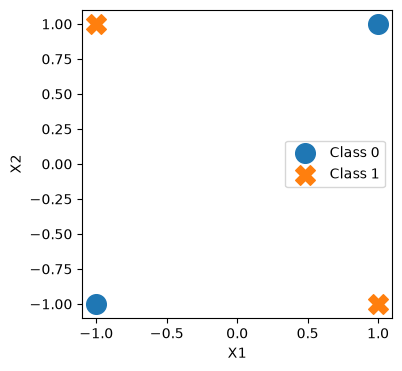

In [2]:
X = np.array([
    [-1, -1],
    [1, -1],
    [-1, 1],
    [1, 1]
])
y = np.array([0, 1, 1, 0])
df = pd.DataFrame(np.column_stack([X, y]), columns=["X1", "X2", "target"])
plt.figure(figsize=(4, 4))
for label, marker in [(0, "o"), (1, "X")]:
    subset = df[df["target"] == label]
    plt.scatter(subset["X1"], subset["X2"], marker=marker, s=200, label=f"Class {label}")
plt.xlabel("X1")
plt.ylabel("X2")
plt.legend();

**Discuss:** What does the sign of $x_1x_2$ tell us?

<details>
<summary>Reveal explanation</summary>

- Same signs → positive product → class 0.
- Opposite signs → negative product → class 1.
- A threshold on the product separates the classes; the boundary is nonlinear in the original inputs.

</details>

In [3]:
df["X1X2"] = df["X1"] * df["X2"]
df

,X1,X2,target,X1X2
0,-1,-1,0,1
1,1,-1,1,-1
2,-1,1,1,-1
3,1,1,0,1


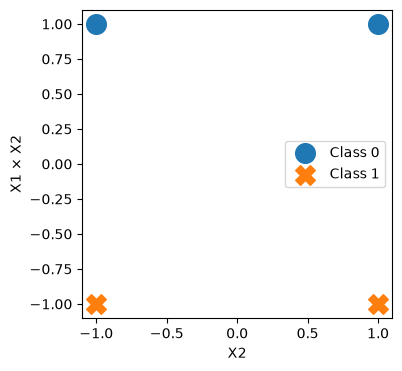

In [4]:
plt.figure(figsize=(4, 4))
for label, marker in [(0, "o"), (1, "X")]:
    subset = df[df["target"] == label]
    plt.scatter(subset["X2"], subset["X1X2"], marker=marker, s=200, label=f"Class {label}")
plt.xlabel("X2")
plt.ylabel("X1 × X2")
plt.legend();

### Extend the idea to more points

- Sample points in all four quadrants.
- Compare logistic regression using the original features and an added interaction.
- These **training scores illustrate representational capacity**, not generalization.

In [5]:
xx, yy = np.meshgrid(np.linspace(-3, 3, 50), np.linspace(-3, 3, 50))
rng = np.random.RandomState(0)
X_xor = rng.randn(200, 2)
y_xor = np.logical_xor(X_xor[:, 0] > 0, X_xor[:, 1] > 0)
# Interaction term
Z = X_xor[:, 0] * X_xor[:, 1]

In [6]:
df = pd.DataFrame({'X': X_xor[:, 0], 'Y': X_xor[:, 1], 'Z': Z, 'Class': y_xor})
df.head()

,X,Y,Z,Class
0,1.764052,0.400157,0.705898,False
1,0.978738,2.240893,2.193247,False
2,1.867558,-0.977278,-1.825123,True
3,0.950088,-0.151357,-0.143803,True
4,-0.103219,0.410599,-0.042382,True


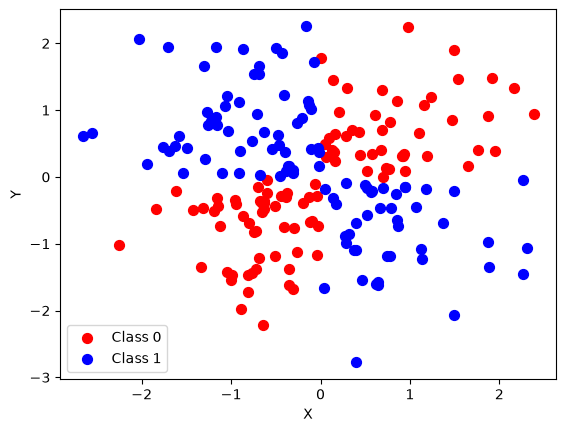

In [7]:
for label, color in [(False, "red"), (True, "blue")]:
    subset = df[df["Class"] == label]
    plt.scatter(subset["X"], subset["Y"], c=color, label=f"Class {int(label)}", s=50)
plt.xlabel("X")
plt.ylabel("Y")
plt.legend();

In [8]:
# Create an interactive 3D scatter plot using plotly
import plotly.express as px
fig = px.scatter_3d(df, x='X', y='Y', z='Z', color='Class', color_continuous_scale=['blue', 'red'])
fig.show();

In [9]:
LogisticRegression().fit(X_xor, y_xor).score(X_xor, y_xor)

0.535

In [10]:
from sklearn.preprocessing import PolynomialFeatures
pipe_xor = make_pipeline(
    PolynomialFeatures(interaction_only=True, include_bias=False), LogisticRegression()
)
pipe_xor.fit(X_xor, y_xor)
pipe_xor.score(X_xor, y_xor)

0.995

In [11]:
feature_names = (
    pipe_xor.named_steps["polynomialfeatures"].get_feature_names_out().tolist()
)

In [12]:
transformed = pipe_xor.named_steps["polynomialfeatures"].transform(X_xor)

In [13]:
pd.DataFrame(
    pipe_xor.named_steps["logisticregression"].coef_.transpose(),
    index=feature_names,
    columns=["Feature coefficient"],
)

,Feature coefficient
x0,-0.028672
x1,0.129459
x0 x1,-5.086461


- Inspect the coefficient on the interaction and compare the two training scores.
- **Linear in the transformed features** can mean nonlinear in the original inputs.
- Coefficient magnitude depends on feature scale; it is not a universal importance measure.

### Crosses of one-hot encoded features

- Multiplying two indicators represents **AND**: both conditions must hold.
- Example: predict parking availability from **area** and **time**.
- Two areas × two times give four combinations:
  - UBC campus at 9am or 7pm.
  - Rogers Arena at 9am or 7pm.
- The effect of time may depend on the area.

**Discuss:** Why might area and time together help more than either feature alone?

<details>
<summary>Reveal explanation</summary>

- A campus morning and an arena evening can have different parking patterns.
- An interaction allows the effect of one input to depend on the other.
- Crosses can grow rapidly; choose plausible combinations and validate them.
- In scikit-learn, products of encoded indicators can be constructed with `PolynomialFeatures(interaction_only=True)`; retain encoding and crossing inside the pipeline.

</details>

## 2. Numeric feature engineering: ratios and binning

- **Dataset:** California housing; each row describes a census block group.
- **Target:** `median_house_value`, not an individual property's sale price.
- Compare ridge regression with different numeric representations.

In [14]:
housing_df = pd.read_csv(DATA_DIR + "california_housing.csv")
housing_df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [15]:
housing_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


**Discuss:** Before fitting ridge, what preprocessing do we need?

<details>
<summary>Reveal explanation</summary>

- Categorical inputs require numeric encoding, such as one-hot encoding.
- Impute missing numeric values and scale inputs for ridge regularization.
- Scaling changes units; it does not create interactions or nonlinear effects.
- Learn preprocessing inside each cross-validation fitting fold.

</details>

In [16]:
train_df, test_df = train_test_split(housing_df, test_size=0.2, random_state=123)

### Build a domain-motivated ratio

- `total_rooms` depends partly on the number of households.
- **Rooms per household** summarizes rooms relative to neighbourhood size.

**Predict:** Could two neighbourhoods with the same total rooms have different ratios?

In [17]:
train_df = train_df.assign(
    rooms_per_household=train_df["total_rooms"] / train_df["households"]
)
test_df = test_df.assign(
    rooms_per_household=test_df["total_rooms"] / test_df["households"]
)

In [18]:
train_df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household
9950,-122.33,38.38,28.0,1020.0,169.0,504.0,164.0,4.5694,287500.0,INLAND,6.219512
3547,-118.60,34.26,18.0,6154.0,1070.0,3010.0,1034.0,5.6392,271500.0,<1H OCEAN,5.951644
4448,-118.21,34.07,47.0,1346.0,383.0,1452.0,371.0,1.7292,191700.0,<1H OCEAN,3.628032
6984,-118.02,33.96,36.0,2071.0,398.0,988.0,404.0,4.6226,219700.0,<1H OCEAN,5.126238
4432,-118.20,34.08,49.0,1320.0,309.0,1405.0,328.0,2.4375,114000.0,<1H OCEAN,4.024390
...,...,...,...,...,...,...,...,...,...,...,...
7763,-118.10,33.91,36.0,726.0,NaN,490.0,130.0,3.6389,167600.0,<1H OCEAN,5.584615
15377,-117.24,33.37,14.0,4687.0,793.0,2436.0,779.0,4.5391,180900.0,<1H OCEAN,6.016688
17730,-121.76,37.33,5.0,4153.0,719.0,2435.0,697.0,5.6306,286200.0,<1H OCEAN,5.958393
15725,-122.44,37.78,44.0,1545.0,334.0,561.0,326.0,3.8750,412500.0,NEAR BAY,4.739264


### Baseline: three numeric inputs

- Use `latitude`, `longitude`, and `rooms_per_household`.
- Impute → standardize → ridge regression.
- Default regression scoring is **R²**; compare mean validation scores and fold variation.

In [19]:
X_train_housing = train_df[["latitude", "longitude", "rooms_per_household"]]
y_train_housing = train_df["median_house_value"]

In [20]:
from sklearn.compose import make_column_transformer

numeric_feats = ["latitude", "longitude", "rooms_per_household"]

preprocessor1 = make_column_transformer(
    (make_pipeline(SimpleImputer(), StandardScaler()), numeric_feats)
)

In [21]:
lr_1 = make_pipeline(preprocessor1, Ridge())
pd.DataFrame(
    cross_validate(lr_1, X_train_housing, y_train_housing, return_train_score=True)
)

,fit_time,score_time,test_score,train_score
0,0.004847,0.001563,0.280028,0.311769
1,0.006174,0.001541,0.325319,0.300464
2,0.001941,0.000707,0.317277,0.301952
3,0.001822,0.000741,0.316798,0.303004
4,0.001772,0.000656,0.260258,0.314840


- Inspect training and validation R² before changing the representation.
- Plot coordinate distributions to understand their ranges and concentration.
- A histogram alone does not show how coordinates relate to price.

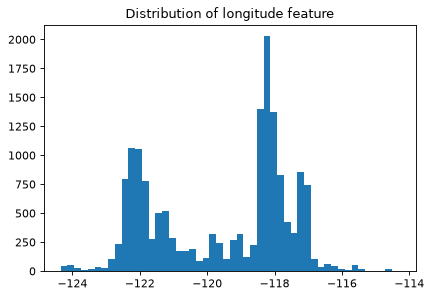

In [22]:
plt.figure(figsize=(6, 4), dpi=80)
plt.hist(train_df["longitude"], bins=50)
plt.title("Distribution of longitude feature");

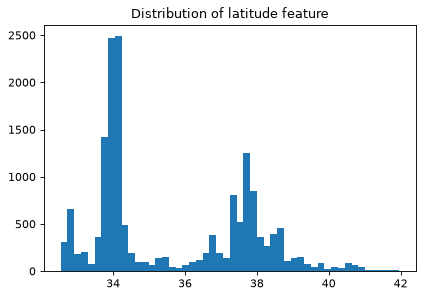

In [23]:
plt.figure(figsize=(6, 4), dpi=80)
plt.hist(train_df["latitude"], bins=50)
plt.title("Distribution of latitude feature");

**Discuss:** What geographic pattern can ridge learn from raw latitude and longitude?

<details>
<summary>Reveal explanation</summary>

- With these inputs, ridge fits an additive linear trend across coordinates.
- It cannot directly represent separate local price peaks.
- Binning gives regions separate effects; crossings can represent joint locations.

</details>

### Bin continuous inputs

- **Binning:** map numeric values to intervals, then one-hot encode the intervals.
- Ridge can assign different offsets to different bins.
- `KBinsDiscretizer` learns bin boundaries inside the pipeline.
- Compare coordinate bins with the raw-coordinate baseline.

In [24]:
from sklearn.preprocessing import KBinsDiscretizer

discretization_feats = ["latitude", "longitude"]
numeric_feats = ["rooms_per_household"]

preprocessor2 = make_column_transformer(
    (KBinsDiscretizer(n_bins=20, encode="onehot"), discretization_feats),
    (make_pipeline(SimpleImputer(), StandardScaler()), numeric_feats),
)

In [25]:
lr_2 = make_pipeline(preprocessor2, Ridge())
pd.DataFrame(
    cross_validate(lr_2, X_train_housing, y_train_housing, return_train_score=True)
)

,fit_time,score_time,test_score,train_score
0,0.013331,0.002151,0.441445,0.456419
1,0.006273,0.001598,0.469299,0.446161
2,0.006750,0.001693,0.479132,0.446869
3,0.006455,0.001744,0.450844,0.453442
4,0.006190,0.001483,0.388169,0.467628


- Compare validation R² and fold variation with the baseline.
- Inspect the transformed columns: each coordinate contributes bin indicators.
- Avoid assuming binning always improves performance.

In [26]:
lr_2.fit(X_train_housing, y_train_housing)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['latitude','longitude','rooms_per_household']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('kbinsdiscretizer', ...), ('pipeline', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis c

In [27]:
pd.DataFrame(
    preprocessor2.fit_transform(X_train_housing).todense(),
    columns=preprocessor2.get_feature_names_out(),
)

,kbinsdiscretizer__latitude_0.0,kbinsdiscretizer__latitude_1.0,kbinsdiscretizer__latitude_2.0,kbinsdiscretizer__latitude_3.0,kbinsdiscretizer__latitude_4.0,kbinsdiscretizer__latitude_5.0,kbinsdiscretizer__latitude_6.0,kbinsdiscretizer__latitude_7.0,kbinsdiscretizer__latitude_8.0,kbinsdiscretizer__latitude_9.0,...,kbinsdiscretizer__longitude_11.0,kbinsdiscretizer__longitude_12.0,kbinsdiscretizer__longitude_13.0,kbinsdiscretizer__longitude_14.0,kbinsdiscretizer__longitude_15.0,kbinsdiscretizer__longitude_16.0,kbinsdiscretizer__longitude_17.0,kbinsdiscretizer__longitude_18.0,kbinsdiscretizer__longitude_19.0,pipeline__rooms_per_household
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.316164
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.209903
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.711852
3,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,-0.117528
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.554621
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16507,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.064307
16508,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.235706
16509,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.212581
16510,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.271037


**Discuss:** Should we also bin rooms per household? What might we gain or lose?

<details>
<summary>Reveal explanation</summary>

- Bins can capture a nonlinear relationship with price.
- Values within a bin become indistinguishable, and predictions can jump at boundaries.
- The number of bins controls flexibility; use validation evidence to choose.

</details>

In [28]:
from sklearn.preprocessing import KBinsDiscretizer

discretization_feats = ["latitude", "longitude", "rooms_per_household"]

preprocessor3 = make_column_transformer(
    (KBinsDiscretizer(n_bins=20, encode="onehot"), discretization_feats),
)

In [29]:
lr_3 = make_pipeline(preprocessor3, Ridge())
pd.DataFrame(
    cross_validate(lr_3, X_train_housing, y_train_housing, return_train_score=True)
)

,fit_time,score_time,test_score,train_score
0,0.010549,0.001734,0.590873,0.571971
1,0.005423,0.001361,0.575793,0.570399
2,0.005390,0.001400,0.578752,0.573544
3,0.005539,0.001302,0.571472,0.574331
4,0.005589,0.001311,0.541507,0.581688


- Compare all three representations using validation R².
- Inspect the fitted bin coefficients to understand the representation.
- Binning adds flexibility; improvement is dataset- and model-dependent.

In [30]:
lr_3.fit(X_train_housing, y_train_housing)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['latitude','longitude','rooms_per_household']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('kbinsdiscretizer', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with th

In [31]:
feature_names = (
    lr_3.named_steps["columntransformer"]
    .named_transformers_["kbinsdiscretizer"]
    .get_feature_names_out()
)

In [32]:
lr_3.named_steps["ridge"].coef_.shape

(60,)

In [33]:
coefs_df = pd.DataFrame(
    lr_3.named_steps["ridge"].coef_.transpose(),
    index=feature_names,
    columns=["coefficient"],
).sort_values("coefficient", ascending=False)
coefs_df.head()

,coefficient
longitude_1.0,211354.997918
latitude_1.0,205062.807876
latitude_0.0,201857.494329
longitude_0.0,190328.582031
longitude_2.0,160292.814993


**Discuss:** What would crosses of latitude and longitude bins represent?

<details>
<summary>Reveal explanation</summary>

- Their products identify two-dimensional geographic cells.
- Separate latitude and longitude effects are additive; crosses permit location-specific effects.
- Twenty bins per coordinate could create 400 joint indicators, with many sparsely observed combinations.
- Validate whether the added flexibility is useful.

</details>

### Feature engineering takeaways

- **Representation matters:** ratios, bins, and interactions expose different patterns.
- Domain knowledge suggests candidate features; validation checks their usefulness.
- Learned transformations belong inside pipelines.
- Text extensions include n-grams, linguistic features, and learned representations.

**Discuss:** If a new feature raises training R² but lowers validation R², should we keep it?

<details>
<summary>Reveal explanation</summary>

- Higher training performance alone is insufficient.
- The new representation may fit noise or add excessive flexibility.
- Compare fold variation and simpler alternatives; reserve test data for final assessment.

</details>

- **Practical workflow:** propose a plausible feature $\to$ build a pipeline $\to$ compare validation results $\to$ retain useful changes.

## 3. Feature selection: why remove columns?

- Engineering can create many new columns.
- Unhelpful inputs can increase computation and opportunities to overfit.
- More columns do not automatically improve generalization.

### What is feature selection?

- Keep a subset of input columns for predicting the target.
- Unlike feature engineering, selection removes inputs rather than constructing a new representation.
- A useful subset depends on the model and the other included inputs.

### Why select features?

- **Interpretability:** fewer inputs can simplify inspection.
- **Computation:** fitting and prediction may be faster.
- **Collection cost:** fewer required measurements may be cheaper.
- **Generalization:** removing unhelpful inputs may reduce overfitting.
- None of these guarantees a higher validation score.

### Compare with an all-feature baseline

- Use the breast cancer dataset: 30 numeric inputs, binary classification.
- Compare accuracy using the same five-fold CV splits.
- Demonstrate **model-based selection** and **recursive feature elimination**.
- Keep supervised selection inside the evaluated pipeline.

In [34]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, random_state=0, test_size=0.5
)

In [35]:
X_train.shape

(284, 30)

In [36]:
pipe_lr_all_feats = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
pipe_lr_all_feats.fit(X_train, y_train)
pd.DataFrame(
    cross_validate(pipe_lr_all_feats, X_train, y_train, return_train_score=True)
).mean()

fit_time       0.001270
score_time     0.000305
test_score     0.968233
train_score    0.987681
dtype: float64

## 4. Model-based selection

- Fit a model that exposes `coef_` or `feature_importances_`.
- Keep features whose importance meets the chosen threshold.
- The selector and final predictor can use different model types.

- `SelectFromModel` acts as a transformer inside a pipeline.
- Here, a random forest supplies importances; the threshold is their median.

**Discuss:** With 30 features, does a median threshold always select exactly 15?

<details>
<summary>Reveal explanation</summary>

- It usually keeps about half, but ties at the threshold can retain more.
- `SelectFromModel` retains importances at or above the threshold; inspect the actual support mask.

</details>

In [37]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel

select_rf = SelectFromModel(
    RandomForestClassifier(n_estimators=100, random_state=42), 
    threshold="median"
)

**Discuss:** Can `SelectFromModel` use KNN directly?

<details>
<summary>Reveal explanation</summary>

- No: KNN does not expose coefficients or feature importances.
- Constructing the selector succeeds, but fitting and transforming requires a supported importance attribute.

</details>

In [38]:
# Unsupported for importance-based selection; retained as a discussion example.
from sklearn.neighbors import KNeighborsClassifier
select_knn = SelectFromModel(KNeighborsClassifier(), threshold="median")

- **Takeaway:** a valid predictor is not necessarily a valid importance-based selector.

**Discuss:** What about a support vector classifier?

<details>
<summary>Reveal explanation</summary>

- A linear-kernel `SVC` exposes `coef_` after fitting.
- The default RBF kernel does not expose input-feature coefficients.
- The choice of kernel therefore matters for this selector.

</details>

In [39]:
# A supported coefficient-based selector (not used in the comparison below).
select_svc = SelectFromModel(SVC(kernel="linear"), threshold="median")

- Use `SVC(kernel="linear")` for coefficient-based selection.

### Evaluate the complete pipeline

- Fit scaling and supervised selection using each CV fitting portion.
- Score on the held-out fold with the same fitted transformations.
- Compare against logistic regression using all features.

In [40]:
pipe_lr_model_based = make_pipeline(
    StandardScaler(), select_rf, LogisticRegression(max_iter=1000)
)

pd.DataFrame(
    cross_validate(pipe_lr_model_based, X_train, y_train, return_train_score=True)
).mean()

fit_time       0.039561
score_time     0.004049
test_score     0.950564
train_score    0.974480
dtype: float64

In [41]:
pipe_lr_model_based.fit(X_train, y_train)
pipe_lr_model_based.named_steps["selectfrommodel"].transform(X_train).shape

(284, 15)

- Inspect the actual number of selected columns.
- Compare validation accuracy, fold variation, and computation with the baseline.
- A smaller subset can be useful even without a score improvement.

## 5. Recursive feature elimination (RFE)

- Fit $\to$ remove the least important input(s) $\to$ refit $\to$ repeat.
- Importances can change after removing a feature.
- Repeated fitting costs more than one-shot selection.

### RFE algorithm

1. Choose the desired number of features, $k$.
2. Fit an estimator and obtain feature importances.
3. Remove the least important feature (`step=1`).
4. Refit and repeat until $k$ remain.

**Discuss:** Why can RFE differ from taking the top $k$ features from one model?

<details>
<summary>Reveal explanation</summary>

- Removing inputs changes the fitted model and the remaining importances.
- Correlated inputs may substitute for one another.
- RFE updates the ranking after each removal rather than fixing it once.

</details>

In [42]:
# RFE reads the logistic regression coefficients from its fitted pipeline.
rfe_estimator = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
importance_getter = "named_steps.logisticregression.coef_"

In [43]:
from sklearn.feature_selection import RFE

rfe = RFE(rfe_estimator, n_features_to_select=5, importance_getter=importance_getter)
rfe.fit(X_train, y_train)
rfe.ranking_

array([16, 12, 19, 13, 23, 20, 10,  1,  9, 22,  2, 25,  5,  7, 15,  4, 26,
       18, 21,  8,  1,  1,  1,  6, 14, 24,  3,  1, 17, 11])

In [44]:
print(rfe.support_)

[False False False False False False False  True False False False False
 False False False False False False False False  True  True  True False
 False False False  True False False]


In [45]:
print("selected features: ", cancer.feature_names[rfe.support_])

selected features:  ['mean concave points' 'worst radius' 'worst texture' 'worst perimeter'
 'worst concave points']


**Discuss:** How should we choose `n_features_to_select`?

<details>
<summary>Reveal explanation</summary>

- Treat the subset size as a model-selection choice.
- `RFECV` compares subset sizes with internal cross-validation.
- Use an outer CV loop to evaluate the full selection-and-prediction procedure.

</details>

### RFECV: choose subset size by validation

- First inspect a selector fitted on training data; this is not a generalization estimate.
- Then evaluate the full pipeline with outer CV.
- For RFECV's internal folds, keep learned scaling inside its estimator too.

In [46]:
from sklearn.feature_selection import RFECV

rfe_cv = RFECV(rfe_estimator, cv=5, importance_getter=importance_getter)
rfe_cv.fit(X_train, y_train)
print("Selected feature count:", rfe_cv.n_features_)
print(cancer.feature_names[rfe_cv.support_])

Selected feature count: 13
['mean concave points' 'mean symmetry' 'radius error' 'perimeter error'
 'area error' 'compactness error' 'fractal dimension error' 'worst radius'
 'worst texture' 'worst perimeter' 'worst area' 'worst concavity'
 'worst concave points']


In [47]:
rfe_pipe = make_pipeline(
    RFECV(rfe_estimator, cv=5, importance_getter=importance_getter),
    RandomForestClassifier(n_estimators=100, random_state=42),
)

pd.DataFrame(cross_validate(rfe_pipe, X_train, y_train, cv=5, return_train_score=True)).mean()

fit_time       0.206599
score_time     0.002085
test_score     0.943609
train_score    1.000000
dtype: float64

- **Inner CV:** chooses the feature count within each outer fitting portion.
- **Outer CV:** evaluates the full procedure on held-out rows.
- Nested fitting is slower; compare the benefit with the all-feature baseline.
- This example also changes the final predictor to a forest, so score differences cannot be attributed to selection alone.

### Optional: other searches

- Forward selection adds features; backward selection removes them.
- Stochastic searches explore alternative subsets using randomness.
- More search increases computation and can overfit validation choices.

## 6. Reflect and check your understanding

- Relevance depends on the other inputs and the fitted model.
- Correlated features can substitute; selected subsets may vary across samples.
- Selection does not establish causation or reveal a uniquely correct subset.

**Discuss:** A colleague selects features using all labels, then cross-validates the reduced dataset. Is that valid?

<details>
<summary>Reveal explanation</summary>

- No: validation labels have already influenced which columns remain.
- Put supervised selection inside the pipeline evaluated by CV.
- Fit the final chosen pipeline on training data, then assess it once on the reserved test set.

</details>

**Discuss:** Two pipelines have similar validation accuracy, but one uses 5 features instead of 30. Which would you choose?

<details>
<summary>Reveal explanation</summary>

- Consider fold variation, measurement cost, fit time, and interpretability.
- Check whether the smaller subset is stable and practical to collect.
- Similar accuracy can justify a simpler pipeline, but does not prove the discarded inputs are universally irrelevant.

</details>

### Main takeaways

- **Engineer** representations that expose useful structure.
- **Select** inputs when the benefits justify the extra procedure.
- **Validate the entire pipeline**, including all learned transformations and selection.